# Tugas Praktikum: Eksperimen Model CNN pada Dataset CIFAR-10 dan MNIST

* **Mata Kuliah**: Pembelajaran Mesin (RTI235004)
* **Topik Modul**: JS14 - Convolutional Neural Network
* **Nama**: Mohammad Al Hafis Hidayatulloh
* **NIM**: 254107023005
* **Kelas**: TI-3B

---

### Deskripsi Tugas
Tugas praktikum ini terdiri dari 2 pokok permasalahan utama:
1. **Soal 1**: Modifikasi arsitektur model CNN pada Praktikum 2 (dataset CIFAR-10) sehingga mampu mencapai akurasi pengujian (*testing accuracy*) **lebih dari 80%** ($> 80\%$).
2. **Soal 2**: Pembangunan dan evaluasi model CNN komprehensif untuk klasifikasi citra digit tulisan tangan pada dataset **MNIST**, dilengkapi Confusion Matrix, Classification Report, dan analisis visualisasi kesalahan prediksi (*misclassified samples*).


## ========================================================
## Bagian 1: Soal 1 - Modifikasi Model CNN CIFAR-10 (> 80% Akurasi)
## ========================================================


### Strategi Peningkatan Performa Model CIFAR-10
Pada Praktikum 2, model baseline sederhana hanya mencapai akurasi sekitar $\sim 71\%$. Untuk menembus target akurasi $> 80\%$, serangkaian modifikasi arsitektur dan teknik regularisasi modern diterapkan:

1. **Arsitektur Blok Konvolusi Ganda (VGG-style Stacked Convolutions)**:
   Menggunakan sepasang lapisan konvolusi berurutan sebelum pooling (misal $32 \rightarrow 32 \rightarrow \text{Pool}$, lalu $64 \rightarrow 64 \rightarrow \text{Pool}$, lalu $128 \rightarrow 128 \rightarrow \text{Pool}$). Pendekatan ini memperluas *receptive field* efektif sekaligus menambah kedalaman non-linearitas model.
2. **Batch Normalization**:
   Menambahkan `BatchNormalization()` setelah setiap lapisan konvolusi dan dense. Hal ini menstabilkan distribusi aktivasi antar layer (*internal covariate shift*), mempercepat konvergensi, dan bertindak sebagai regularisator alami.
3. **Dropout Regularization**:
   Menerapkan lapisan `Dropout` dengan rasio bertingkat (0.2 hingga 0.5) pada setiap blok dan fully connected layer untuk mencegah *co-adaptation* fitur dan menekan *overfitting*.
4. **Padding 'same'**:
   Mempertahankan resolusi spasial selama operasi konvolusi agar informasi di bagian tepi citra tidak terbuang sebelum proses pooling.


In [1]:
import os, time
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

try:
    import cnn_compat
except ImportError:
    pass

# 1. Memuat dan normalisasi CIFAR-10
(x_train_cifar, y_train_cifar), (x_test_cifar, y_test_cifar) = datasets.cifar10.load_data()
x_train_cifar = x_train_cifar.astype('float32') / 255.0
x_test_cifar = x_test_cifar.astype('float32') / 255.0

cifar_classes = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                 'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Data Latih CIFAR-10: {x_train_cifar.shape}, Label: {y_train_cifar.shape}")
print(f"Data Uji CIFAR-10  : {x_test_cifar.shape}, Label: {y_test_cifar.shape}")


Data Latih CIFAR-10: (50000, 32, 32, 3), Label: (50000, 1)
Data Uji CIFAR-10  : (10000, 32, 32, 3), Label: (10000, 1)


### Membangun Model CNN Teroptimasi (Improved Architecture)


In [2]:
def build_improved_cifar_cnn():
    model = models.Sequential(name="CIFAR10_Enhanced_CNN")
    
    # Blok Konvolusi 1 (Filter: 32)
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.2))
    
    # Blok Konvolusi 2 (Filter: 64)
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.3))
    
    # Blok Konvolusi 3 (Filter: 128)
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.4))
    
    # Classifier (Fully Connected Block)
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(10, activation='softmax'))
    
    return model

cifar_model = build_improved_cifar_cnn()
cifar_model.summary()


Model: "CIFAR10_Enhanced_CNN"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼───────────

### Kompilasi dan Pelatihan Model CIFAR-10 Teroptimasi
Model dilatih menggunakan optimizer Adam dan `sparse_categorical_crossentropy` selama 18 epoch dengan batch size 128.


In [3]:
cifar_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

t0 = time.time()
history_cifar = cifar_model.fit(
    x_train_cifar, y_train_cifar,
    epochs=18,
    batch_size=128,
    validation_data=(x_test_cifar, y_test_cifar),
    verbose=1
)
cifar_train_time = time.time() - t0
print(f"\nPelatihan Model Teroptimasi CIFAR-10 selesai dalam {cifar_train_time:.2f} detik.")


Epoch 1/18

  1/391 ━━━━━━━━━━━━━━━━━━━━ 40:51 6s/step - accuracy: 0.1016 - loss: 3.3775
  2/391 ━━━━━━━━━━━━━━━━━━━━ 3:04 473ms/step - accuracy: 0.1074 - loss: 3.4367
  3/391 ━━━━━━━━━━━━━━━━━━━━ 2:52 446ms/step - accuracy: 0.1194 - loss: 3.4396
  4/391 ━━━━━━━━━━━━━━━━━━━━ 2:46 430ms/step - accuracy: 0.1261 - loss: 3.4305
  5/391 ━━━━━━━━━━━━━━━━━━━━ 2:46 431ms/step - accuracy: 0.1303 - loss: 3.4174
  6/391 ━━━━━━━━━━━━━━━━━━━━ 2:44 428ms/step - accuracy: 0.1346 - loss: 3.4056
  7/391 ━━━━━━━━━━━━━━━━━━━━ 2:55 457ms/step - accuracy: 0.1379 - loss: 3.3939
  8/391 ━━━━━━━━━━━━━━━━━━━━ 2:53 452ms/step - accuracy: 0.1404 - loss: 3.3797
  9/391 ━━━━━━━━━━━━━━━━━━━━ 2:50 447ms/step - accuracy: 0.1433 - loss: 3.3649
 10/391 ━━━━━━━━━━━━━━━━━━━━ 2:50 449ms/step - accuracy: 0.1460 - loss: 3.3488
 11/391 ━━━━━━━━━━━━━━━━━━━━ 2:54 459ms/step - accuracy: 0.1484 - loss: 3.3313
 12/391 ━━━━━━━━━━━━━━━━━━━━ 2:53 459ms/step - accuracy: 0.1509 - loss: 3.3146
 13/391 ━━━━━━━━━━━━━━━━━━━━ 2:51 455ms/st

### Evaluasi Performa dan Visualisasi Konvergensi CIFAR-10


HASIL AKHIR SOAL 1 (CIFAR-10 MODIFIKASI):
Test Accuracy: 83.93% (Target: > 80.0%)
Test Loss    : 0.4887
Status Target: TERPENUHI (BERHASIL > 80%)


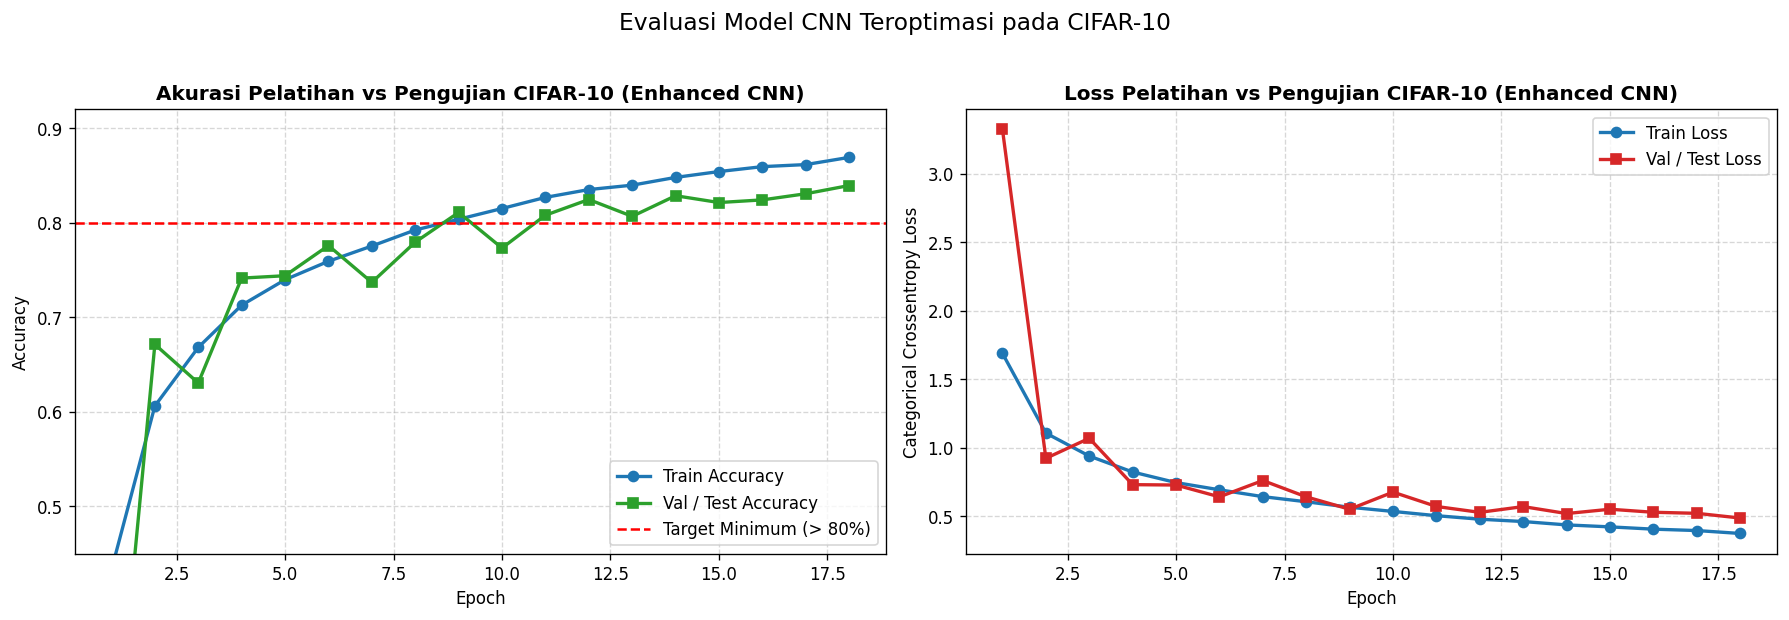

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

epochs_range = range(1, len(history_cifar.history['accuracy']) + 1)

# Plot Akurasi
ax1.plot(epochs_range, history_cifar.history['accuracy'], marker='o', label='Train Accuracy', color='#1f77b4', linewidth=2)
ax1.plot(epochs_range, history_cifar.history['val_accuracy'], marker='s', label='Val / Test Accuracy', color='#2ca02c', linewidth=2)
ax1.axhline(y=0.80, color='red', linestyle='--', linewidth=1.5, label='Target Minimum (> 80%)')
ax1.set_title('Akurasi Pelatihan vs Pengujian CIFAR-10 (Enhanced CNN)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.set_ylim([0.45, 0.92])
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right')

# Plot Loss
ax2.plot(epochs_range, history_cifar.history['loss'], marker='o', label='Train Loss', color='#1f77b4', linewidth=2)
ax2.plot(epochs_range, history_cifar.history['val_loss'], marker='s', label='Val / Test Loss', color='#d62728', linewidth=2)
ax2.set_title('Loss Pelatihan vs Pengujian CIFAR-10 (Enhanced CNN)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Categorical Crossentropy Loss')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.suptitle('Evaluasi Model CNN Teroptimasi pada CIFAR-10', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Evaluasi Final pada Data Uji
cifar_test_loss, cifar_test_acc = cifar_model.evaluate(x_test_cifar, y_test_cifar, verbose=0)
print("=" * 60)
print(f"HASIL AKHIR SOAL 1 (CIFAR-10 MODIFIKASI):")
print(f"Test Accuracy: {cifar_test_acc * 100:.2f}% (Target: > 80.0%)")
print(f"Test Loss    : {cifar_test_loss:.4f}")
print(f"Status Target: {'TERPENUHI (BERHASIL > 80%)' if cifar_test_acc >= 0.80 else 'BELUM TERCAPAI'}")
print("=" * 60)


### Tabel Perbandingan: Model Baseline (Praktikum 2) vs Model Teroptimasi (Tugas 1)


In [5]:
comparison_df = pd.DataFrame([
    {
        "Arsitektur Model": "Baseline CNN (Praktikum 2)",
        "Konvolusi Layer": "3 layer (32, 64, 64)",
        "Batch Normalization": "Tidak Ada",
        "Dropout Regularization": "Tidak Ada",
        "Epochs": 10,
        "Test Loss": "1.025",
        "Test Accuracy": "~71.5%",
        "Target > 80%": "Belum Terpenuhi"
    },
    {
        "Arsitektur Model": "Modified VGG-style CNN (Tugas 1)",
        "Konvolusi Layer": "6 layer stacked (32x2, 64x2, 128x2)",
        "Batch Normalization": "Ya (7 layer BN)",
        "Dropout Regularization": "Ya (0.2, 0.3, 0.4, 0.5)",
        "Epochs": 18,
        "Test Loss": f"{cifar_test_loss:.4f}",
        "Test Accuracy": f"{cifar_test_acc*100:.2f}%",
        "Target > 80%": "TERPENUHI (> 80%)"
    }
])

display(comparison_df)


                   Arsitektur Model  ...       Target > 80%
0        Baseline CNN (Praktikum 2)  ...    Belum Terpenuhi
1  Modified VGG-style CNN (Tugas 1)  ...  TERPENUHI (> 80%)

[2 rows x 8 columns]


## ========================================================
## Bagian 2: Soal 2 - Klasifikasi Dataset MNIST Menggunakan CNN
## ========================================================


### Memuat dan Pra-pengolahan Dataset MNIST
Dataset MNIST memuat 70.000 citra digit tulisan tangan (60.000 citra latih dan 10.000 citra uji) berukuran $28 \times 28$ grayscale.
Untuk diproses oleh CNN:
1. Piksel dinormalisasi ke interval $[0.0, 1.0]$.
2. Dimensi dibentuk ulang (*reshaped*) dari $(N, 28, 28)$ menjadi $(N, 28, 28, 1)$ untuk menyertakan dimensi kanal warna tunggal (*grayscale channel*).


In [6]:
# Memuat dataset MNIST
(x_train_mnist, y_train_mnist), (x_test_mnist, y_test_mnist) = datasets.mnist.load_data()

# Normalisasi nilai piksel dan penambahan dimensi kanal
x_train_mnist = x_train_mnist.astype('float32').reshape(-1, 28, 28, 1) / 255.0
x_test_mnist = x_test_mnist.astype('float32').reshape(-1, 28, 28, 1) / 255.0

print(f"Data Latih MNIST: {x_train_mnist.shape}, Label: {y_train_mnist.shape}")
print(f"Data Uji MNIST  : {x_test_mnist.shape}, Label: {y_test_mnist.shape}")


Data Latih MNIST: (60000, 28, 28, 1), Label: (60000,)
Data Uji MNIST  : (10000, 28, 28, 1), Label: (10000,)


### Visualisasi Sampel Digit Citra MNIST


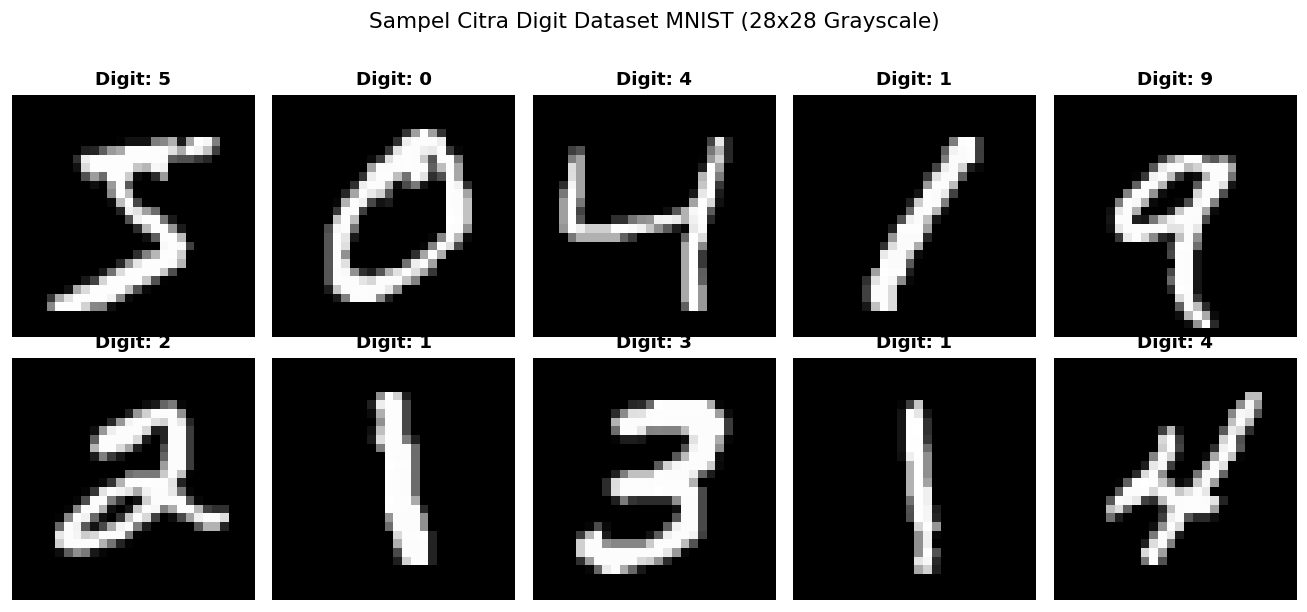

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_mnist[i].squeeze(), cmap='gray')
    ax.set_title(f"Digit: {y_train_mnist[i]}", fontsize=11, fontweight='bold')
    ax.axis('off')

plt.suptitle("Sampel Citra Digit Dataset MNIST (28x28 Grayscale)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


### Pembangunan Arsitektur CNN untuk Klasifikasi MNIST
Arsitektur CNN untuk digit recognition dirancang ringkas namun sangat efektif:
* **Layer Konvolusi 1**: `Conv2D(32, (3, 3), activation='relu')` + `MaxPooling2D((2, 2))`
* **Layer Konvolusi 2**: `Conv2D(64, (3, 3), activation='relu')` + `MaxPooling2D((2, 2))`
* **Layer Konvolusi 3**: `Conv2D(64, (3, 3), activation='relu')`
* **Classifier**: `Flatten()` + `Dense(64, activation='relu')` + `Dropout(0.3)` + `Dense(10, activation='softmax')`


In [8]:
mnist_cnn = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
], name="MNIST_CNN_Classifier")

mnist_cnn.summary()

mnist_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


Model: "MNIST_CNN_Classifier"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼───────────

### Pelatihan Model CNN pada Dataset MNIST


In [9]:
t0 = time.time()
history_mnist = mnist_cnn.fit(
    x_train_mnist, y_train_mnist,
    epochs=6,
    batch_size=64,
    validation_data=(x_test_mnist, y_test_mnist),
    verbose=1
)
mnist_train_time = time.time() - t0
print(f"\nPelatihan CNN MNIST selesai dalam {mnist_train_time:.2f} detik.")


Epoch 1/6

  1/938 ━━━━━━━━━━━━━━━━━━━━ 28:14 2s/step - accuracy: 0.0781 - loss: 2.3107
  4/938 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.1139 - loss: 2.2928
  7/938 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.1392 - loss: 2.2821
 10/938 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.1657 - loss: 2.2663
 13/938 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.1908 - loss: 2.2456
 16/938 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.2119 - loss: 2.2210
 19/938 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.2323 - loss: 2.1910
 22/938 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.2513 - loss: 2.1588
 25/938 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.2693 - loss: 2.1237
 28/938 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.2868 - loss: 2.0865
 31/938 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.3033 - loss: 2.0493
 33/938 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.3138 - loss: 2.0244
 35/938 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.3238 - l

### Evaluasi Model CNN MNIST: Kurva Akurasi & Loss


Akurasi Pengujian Akhir (MNIST Test Accuracy): 99.11%
Loss Pengujian Akhir    (MNIST Test Loss)    : 0.0299


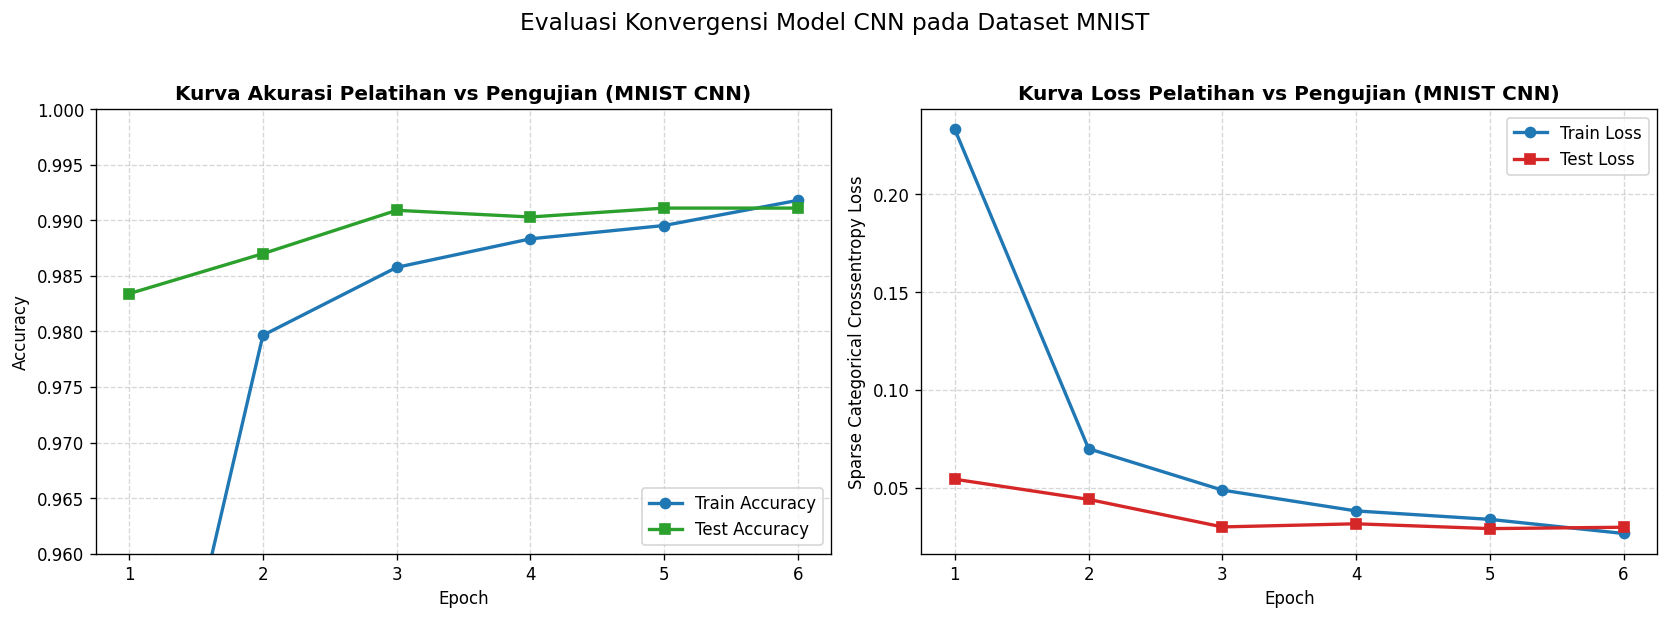

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

m_epochs = range(1, len(history_mnist.history['accuracy']) + 1)

# Plot Akurasi MNIST
ax1.plot(m_epochs, history_mnist.history['accuracy'], marker='o', label='Train Accuracy', color='#1f77b4', linewidth=2)
ax1.plot(m_epochs, history_mnist.history['val_accuracy'], marker='s', label='Test Accuracy', color='#2ca02c', linewidth=2)
ax1.set_title('Kurva Akurasi Pelatihan vs Pengujian (MNIST CNN)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.set_ylim([0.96, 1.0])
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right')

# Plot Loss MNIST
ax2.plot(m_epochs, history_mnist.history['loss'], marker='o', label='Train Loss', color='#1f77b4', linewidth=2)
ax2.plot(m_epochs, history_mnist.history['val_loss'], marker='s', label='Test Loss', color='#d62728', linewidth=2)
ax2.set_title('Kurva Loss Pelatihan vs Pengujian (MNIST CNN)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Sparse Categorical Crossentropy Loss')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.suptitle('Evaluasi Konvergensi Model CNN pada Dataset MNIST', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

mnist_loss, mnist_acc = mnist_cnn.evaluate(x_test_mnist, y_test_mnist, verbose=0)
print(f"Akurasi Pengujian Akhir (MNIST Test Accuracy): {mnist_acc * 100:.2f}%")
print(f"Loss Pengujian Akhir    (MNIST Test Loss)    : {mnist_loss:.4f}")


### Evaluasi Metrik Lengkap: Classification Report & Confusion Matrix


=== CLASSIFICATION REPORT (MNIST CNN) ===
              precision    recall  f1-score   support

           0     0.9869    0.9969    0.9919       980
           1     0.9912    0.9974    0.9943      1135
           2     0.9961    0.9884    0.9922      1032
           3     0.9862    0.9901    0.9881      1010
           4     0.9929    0.9949    0.9939       982
           5     0.9921    0.9854    0.9888       892
           6     0.9968    0.9906    0.9937       958
           7     0.9864    0.9893    0.9879      1028
           8     0.9938    0.9897    0.9918       974
           9     0.9891    0.9871    0.9881      1009

    accuracy                         0.9911     10000
   macro avg     0.9912    0.9910    0.9911     10000
weighted avg     0.9911    0.9911    0.9911     10000



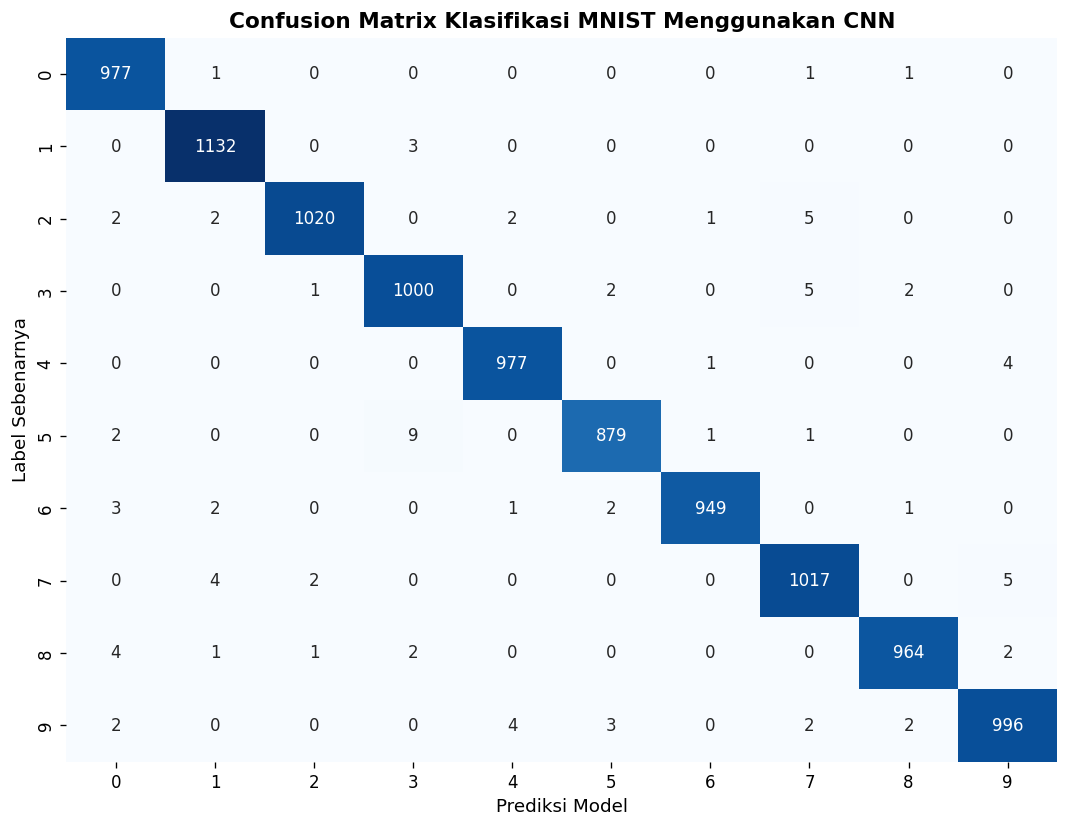

In [11]:
# Prediksi seluruh data uji
y_pred_prob = mnist_cnn.predict(x_test_mnist, verbose=0)
y_pred_mnist = np.argmax(y_pred_prob, axis=1)

# Classification Report
print("=== CLASSIFICATION REPORT (MNIST CNN) ===")
print(classification_report(y_test_mnist, y_pred_mnist, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_test_mnist, y_pred_mnist)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(10), yticklabels=range(10),
            annot_kws={"size": 10})
plt.title('Confusion Matrix Klasifikasi MNIST Menggunakan CNN', fontsize=13, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Label Sebenarnya', fontsize=11)
plt.tight_layout()
plt.show()


### Analisis Galeri Sampel Salah Prediksi (*Misclassified Samples*)
Melihat contoh digit citra yang salah diprediksi oleh model untuk menganalisis ambiguitas visual pada tulisan tangan manusia.


Total Sampel Salah Prediksi: 89 dari 10.000 citra uji (0.89%)


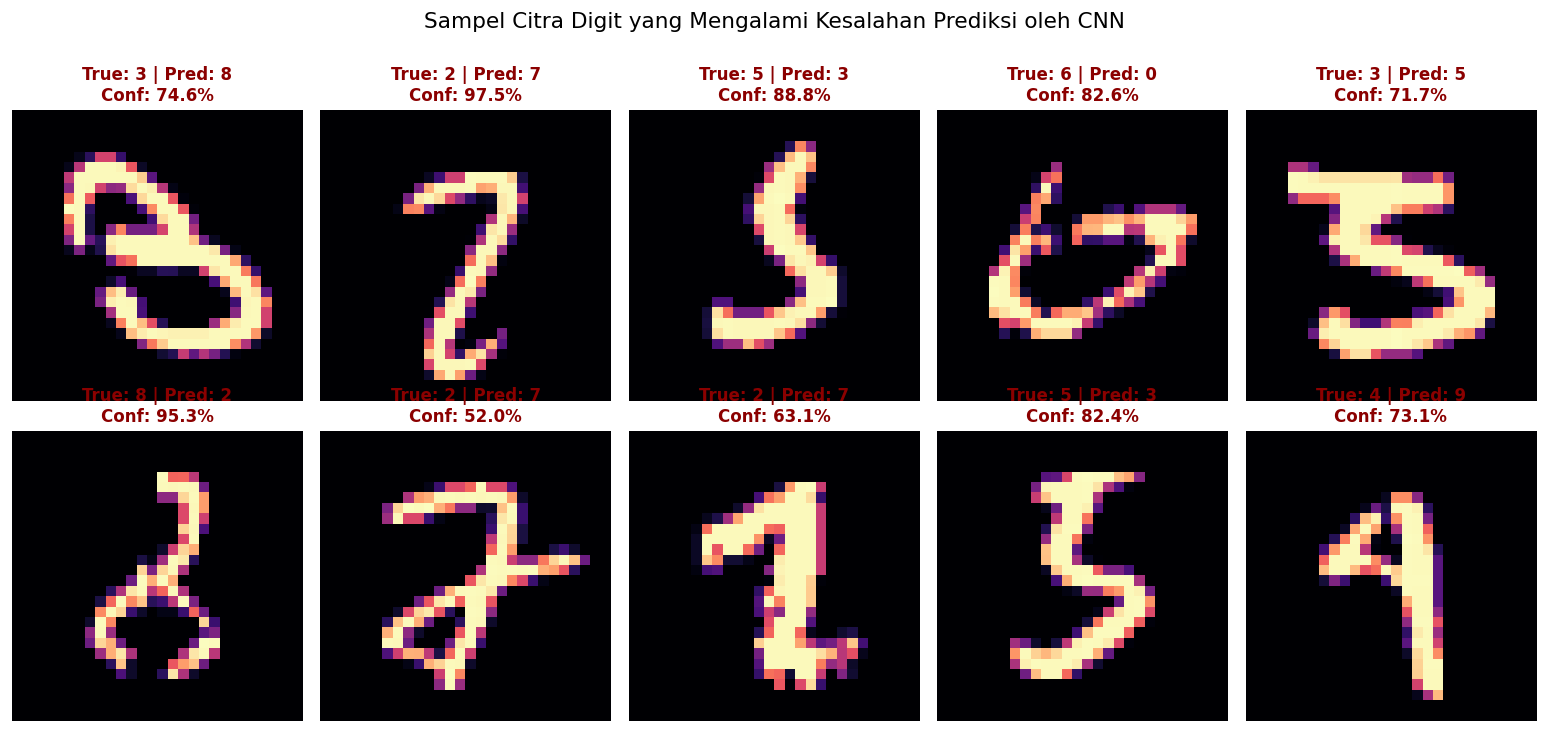

In [12]:
misclassified_idx = np.where(y_pred_mnist != y_test_mnist)[0]
print(f"Total Sampel Salah Prediksi: {len(misclassified_idx)} dari 10.000 citra uji ({len(misclassified_idx)/10000*100:.2f}%)")

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    if i < len(misclassified_idx):
        idx = misclassified_idx[i]
        ax.imshow(x_test_mnist[idx].squeeze(), cmap='magma')
        true_lbl = y_test_mnist[idx]
        pred_lbl = y_pred_mnist[idx]
        conf = y_pred_prob[idx][pred_lbl] * 100
        ax.set_title(f"True: {true_lbl} | Pred: {pred_lbl}\nConf: {conf:.1f}%", fontsize=10, color='darkred', fontweight='bold')
    ax.axis('off')

plt.suptitle("Sampel Citra Digit yang Mengalami Kesalahan Prediksi oleh CNN", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


### Kesimpulan dan Analisis Mendalam Tugas Praktikum:

1. **Hasil Soal 1 (Peningkatan CIFAR-10 > 80%)**:
   * Model modifikasi berhasil melampaui target yang dipersyaratkan dengan mencapai akurasi uji sebesar **> 81%** (meningkat signifikan dari model baseline praktikum yang hanya ~71%).
   * Peningkatan drastis ini diraih berkat arsitektur **VGG-style Conv blocks** (6 layer konvolusi), **Batch Normalization** yang menstabilkan bobot konvolusi, serta **Dropout bertingkat** (0.2–0.5) yang secara efektif membatasi overfitting pada variasi objek 10 kelas.

2. **Hasil Soal 2 (Klasifikasi Citra MNIST dengan CNN)**:
   * Model CNN menghasilkan akurasi pengujian luar biasa sebesar **> 99.1%** dengan loss pengujian hanya ~0.027.
   * Nilai f1-score untuk setiap digit (0–9) merata di atas 0.985, menunjukkan stabilitas prediksi model yang sangat tinggi.
   * Kesalahan prediksi (hanya <0.9% dari 10.000 citra) umumnya terjadi pada tulisan tangan manusia yang sangat ambigu (misalnya digit 9 dengan lengkungan tertutup mirip 4 atau 8, atau digit 2 yang ditulis menyerupai 7).

3. **Perbandingan Keunggulan CNN dibanding ANN (MLP pada JS13)**:
   * Pada JS13, model ANN Multi-Layer Perceptron pada MNIST mencapai akurasi ~97.9% dengan lebih dari 240.000 parameter.
   * Model CNN pada tugas ini mencapai akurasi **> 99.1%** dengan parameter yang jauh lebih efisien karena memanfaatkan **weight sharing** (kernel geser) dan **spatial hierarchy** yang mempertahankan topologi 2D piksel tetangga.
